In [15]:
import os
from src.utils import load_util
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set working directory
os.chdir("D:/DataspellProjects/foodRAG")  # Change to the root directory of the project
cwd = os.getcwd()
print("Current Working Directory:", cwd)

Current Working Directory: D:\DataspellProjects\foodRAG


In [2]:
# Output Path
data_path = './data/hummus_k_1_1'

## Raw HUMMUS data
data_location = '...'
graph_location = '...'
additional_location = '...'

In [3]:
# Load (init if necessary) the data
# hummus_data = load_util.get_hummus(data_location, graph_location, additional_location, data_path=data_path,
#                                    discard_non_tagged_recipes=False, n_clusters=-1, k_user=1, k_recipe=1,
#                                    food_class_strategy='None', add_additional_meal_type_labels=False,
#                                    clean_food_category=True, similarity_thresholds=False, include_usda=True,
#                                    do_annotate_meal_type=False, create_random_meal_types=False)

# Load the current recipes data
hummus_data = load_util.get_current_hummus(data_path)

In [4]:
recipes = hummus_data['recipes_df']

# Add column with the number of tags
recipes['#tags'] = recipes['tags'].apply(lambda x: len(x) if isinstance(x, list) else 0)

print(recipes.columns.str.strip())

Index(['recipe_id', 'title', 'description', 'author_id', 'duration',
       'directions', 'ingredients', 'serves', 'last_changed_date',
       'food_kg_locator', 'recipe_url', 'tags', 'average_rating',
       'number_of_ratings', 'servingsPerRecipe', 'servingSize [g]',
       'calories [kcal]', 'caloriesFromFat [kcal]', 'totalFat [g]',
       'saturatedFat [g]', 'cholesterol [mg]', 'sodium [mg]',
       'totalCarbohydrate [g]', 'dietaryFiber [g]', 'sugars [g]',
       'protein [g]', 'who_score', 'fsa_score', 'nutri_score',
       'normalization_comment', 'direction_size', 'ingredients_sizes',
       'ingredient_names', '#tags'],
      dtype='object')


In [73]:
# hummus_heatmap_full.png
plt.rcParams.update({'font.size': 12})
sns.set(font_scale=0.8)

plot_data = pd.DataFrame(recipes)
plot_data = plot_data.rename(
    columns={'direction_size': '#steps',
             'ingredients_sizes': '#ingred',
             'number_of_ratings': '#ratings',
             'average_rating': 'avgRating',
             'totalCarbohydrate [g]': 'carbs [g]',
             'caloriesFromFat [kcal]': 'calFromFat [kcal]',
             'dietaryFiber [g]': 'fiber [g]',
             }
)

plot_data.drop(['recipe_id', 'title', 'description', 'author_id', 'duration',
                'directions', 'ingredients', 'serves', 'last_changed_date',
                'food_kg_locator', 'recipe_url', 'tags', 'servingsPerRecipe',
                'normalization_comment', 'ingredient_names', 'who_score'], axis=1, inplace=True)

plt.figure(figsize=(14, 10), dpi=700)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

sns.heatmap(
    plot_data.corr().round(2),
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    cmap="coolwarm",
    vmin=-1,          # fixed minimum
    vmax=1,           # fixed maximum
    center=0,         # white at zero
    cbar=True
)

plt.tight_layout()
plt.show()

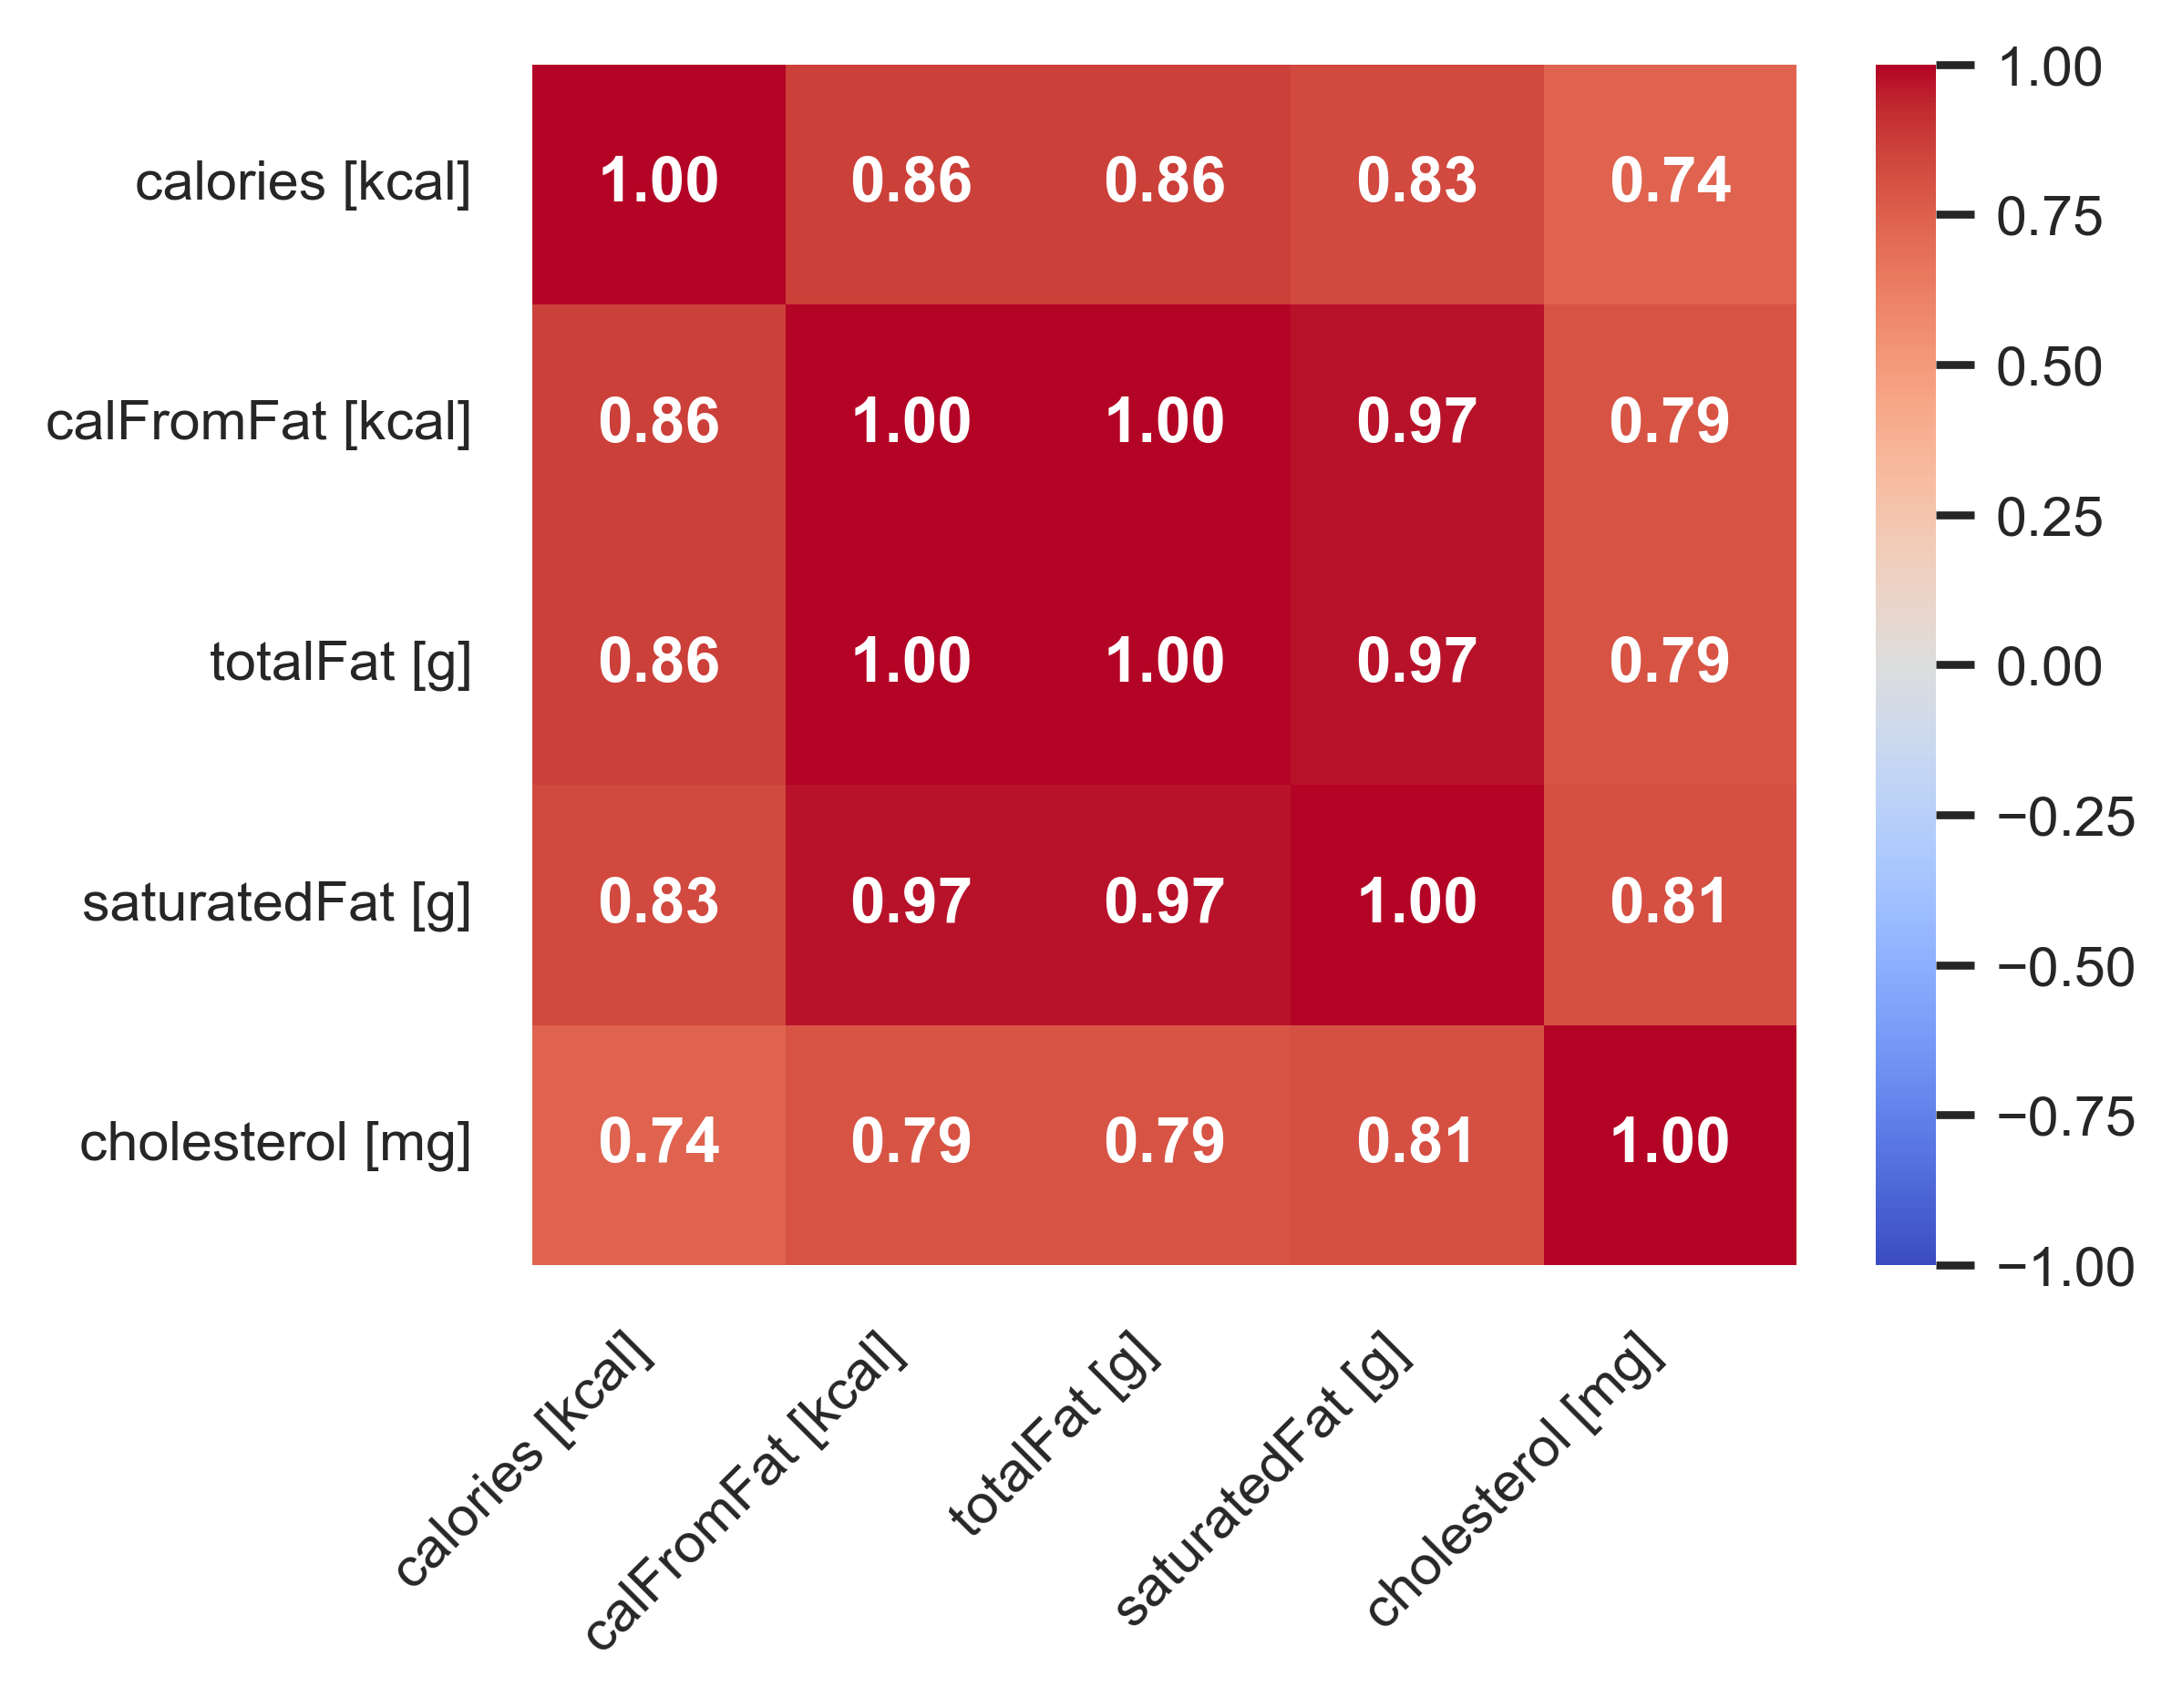

In [74]:
# hummus_heatmap_fats.png
plt.rcParams.update({'font.size': 15})

plot_data = pd.DataFrame(recipes)
plot_data = plot_data.rename(
    columns={'direction_size': '#steps',
             'ingredients_sizes': '#ingred',
             'number_of_ratings': '#ratings',
             'average_rating': 'avgRating',
             'totalCarbohydrate [g]': 'carbs [g]',
             'caloriesFromFat [kcal]': 'calFromFat [kcal]',
             'dietaryFiber [g]': 'fiber [g]',
             }
)

# choose features
x_features = ['calories [kcal]', 'calFromFat [kcal]','totalFat [g]', 'saturatedFat [g]', 'cholesterol [mg]']
y_features = ['calories [kcal]', 'calFromFat [kcal]','totalFat [g]', 'saturatedFat [g]', 'cholesterol [mg]']

all_features = list(dict.fromkeys(y_features + x_features))
corr = plot_data[all_features].corr()
corr = corr.loc[y_features, x_features]

plt.figure(figsize=(5, 4), dpi=500)

sns.heatmap(
    corr.round(2),
    annot=True,
    fmt=".2f",
    annot_kws={"weight": "bold", "size": 10},
    cmap="coolwarm",
    vmin=-1,          # fixed minimum
    vmax=1,           # fixed maximum
    center=0,         # white at zero
    cbar=True
)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

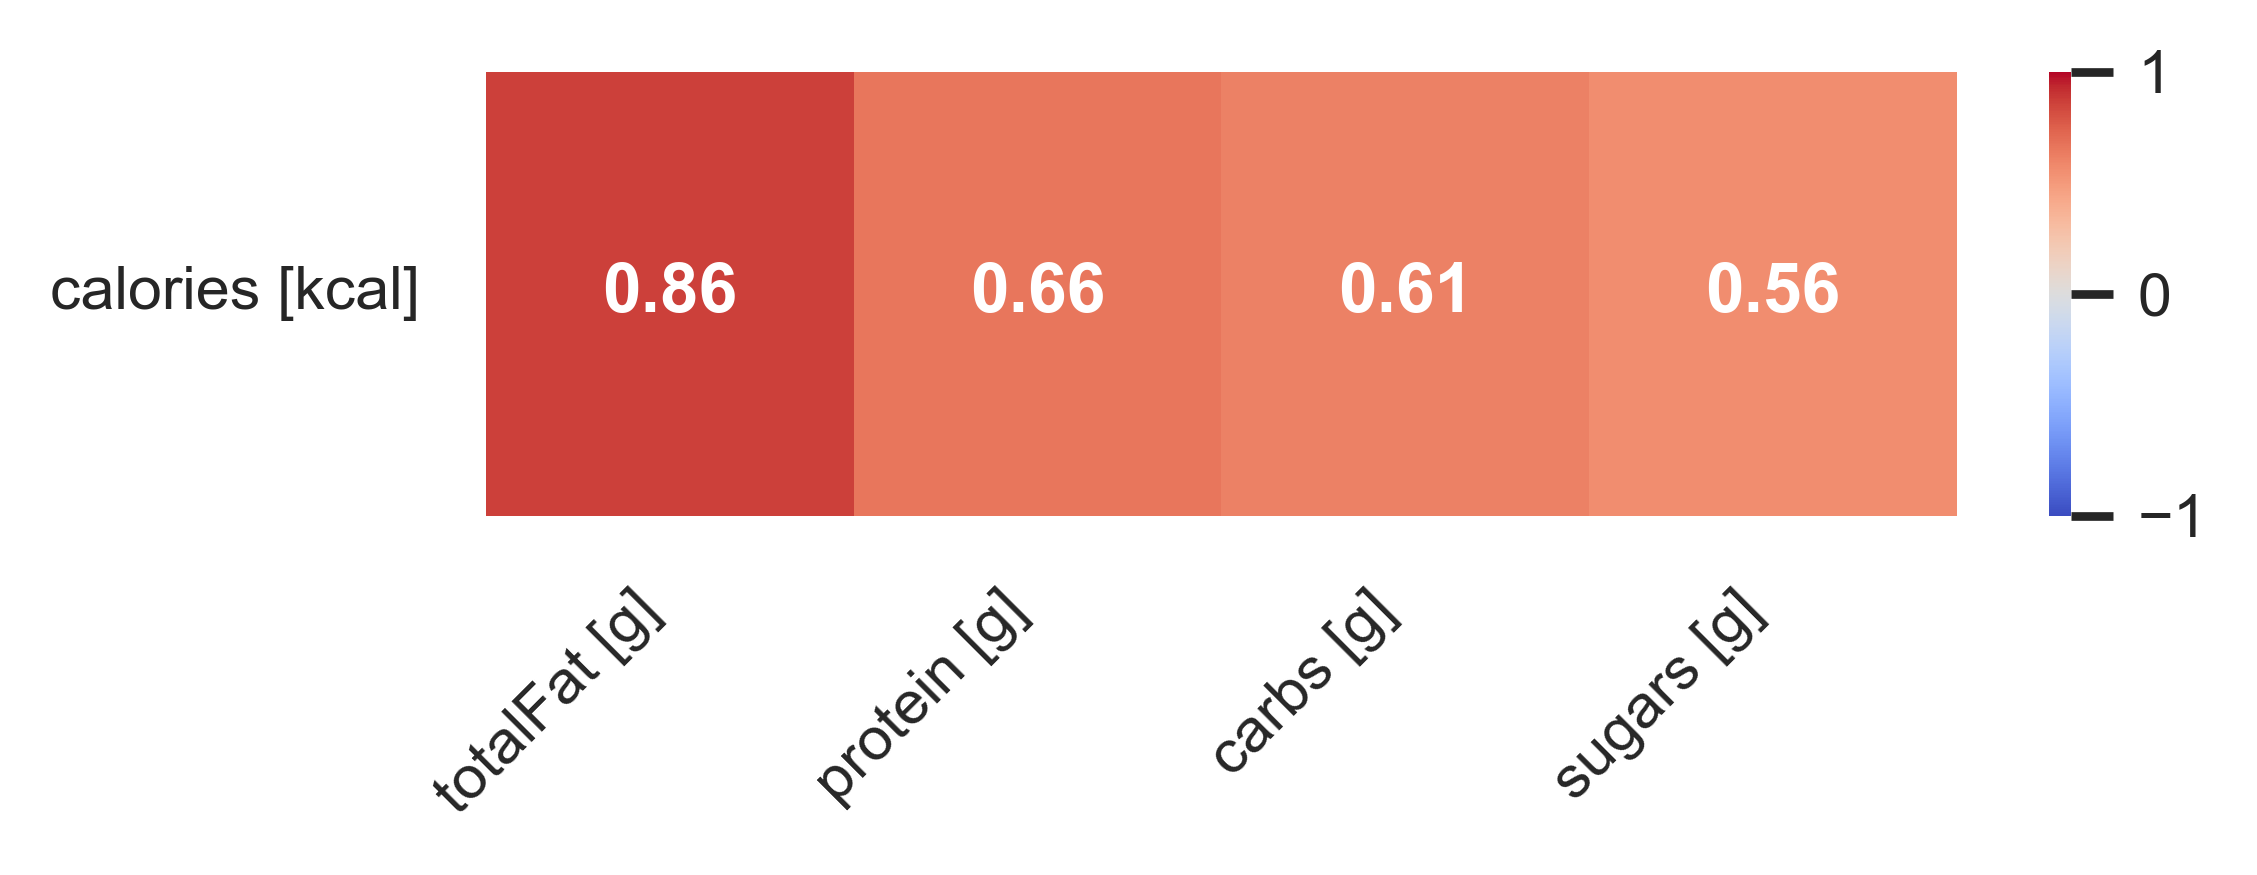

In [75]:
# hummus_heatmap_energy_nutrients.png
plt.rcParams.update({'font.size': 15})

plot_data = pd.DataFrame(recipes)
plot_data = plot_data.rename(
    columns={'direction_size': '#steps',
             'ingredients_sizes': '#ingred',
             'number_of_ratings': '#ratings',
             'average_rating': 'avgRating',
             'totalCarbohydrate [g]': 'carbs [g]',
             'caloriesFromFat [kcal]': 'calFromFat [kcal]',
             'dietaryFiber [g]': 'fiber [g]',
             }
)

# choose features
x_features = ['totalFat [g]', 'protein [g]', 'carbs [g]', 'sugars [g]']
y_features = ['calories [kcal]']

all_features = list(dict.fromkeys(y_features + x_features))
corr = plot_data[all_features].corr()
corr = corr.loc[y_features, x_features]

plt.figure(figsize=(5, 2), dpi=500)

sns.heatmap(
    corr.round(2),
    annot=True,
    fmt=".2f",
    annot_kws={"weight": "bold", "size": 10},
    cmap="coolwarm",
    vmin=-1,          # fixed minimum
    vmax=1,           # fixed maximum
    center=0,         # white at zero
    cbar=True
)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

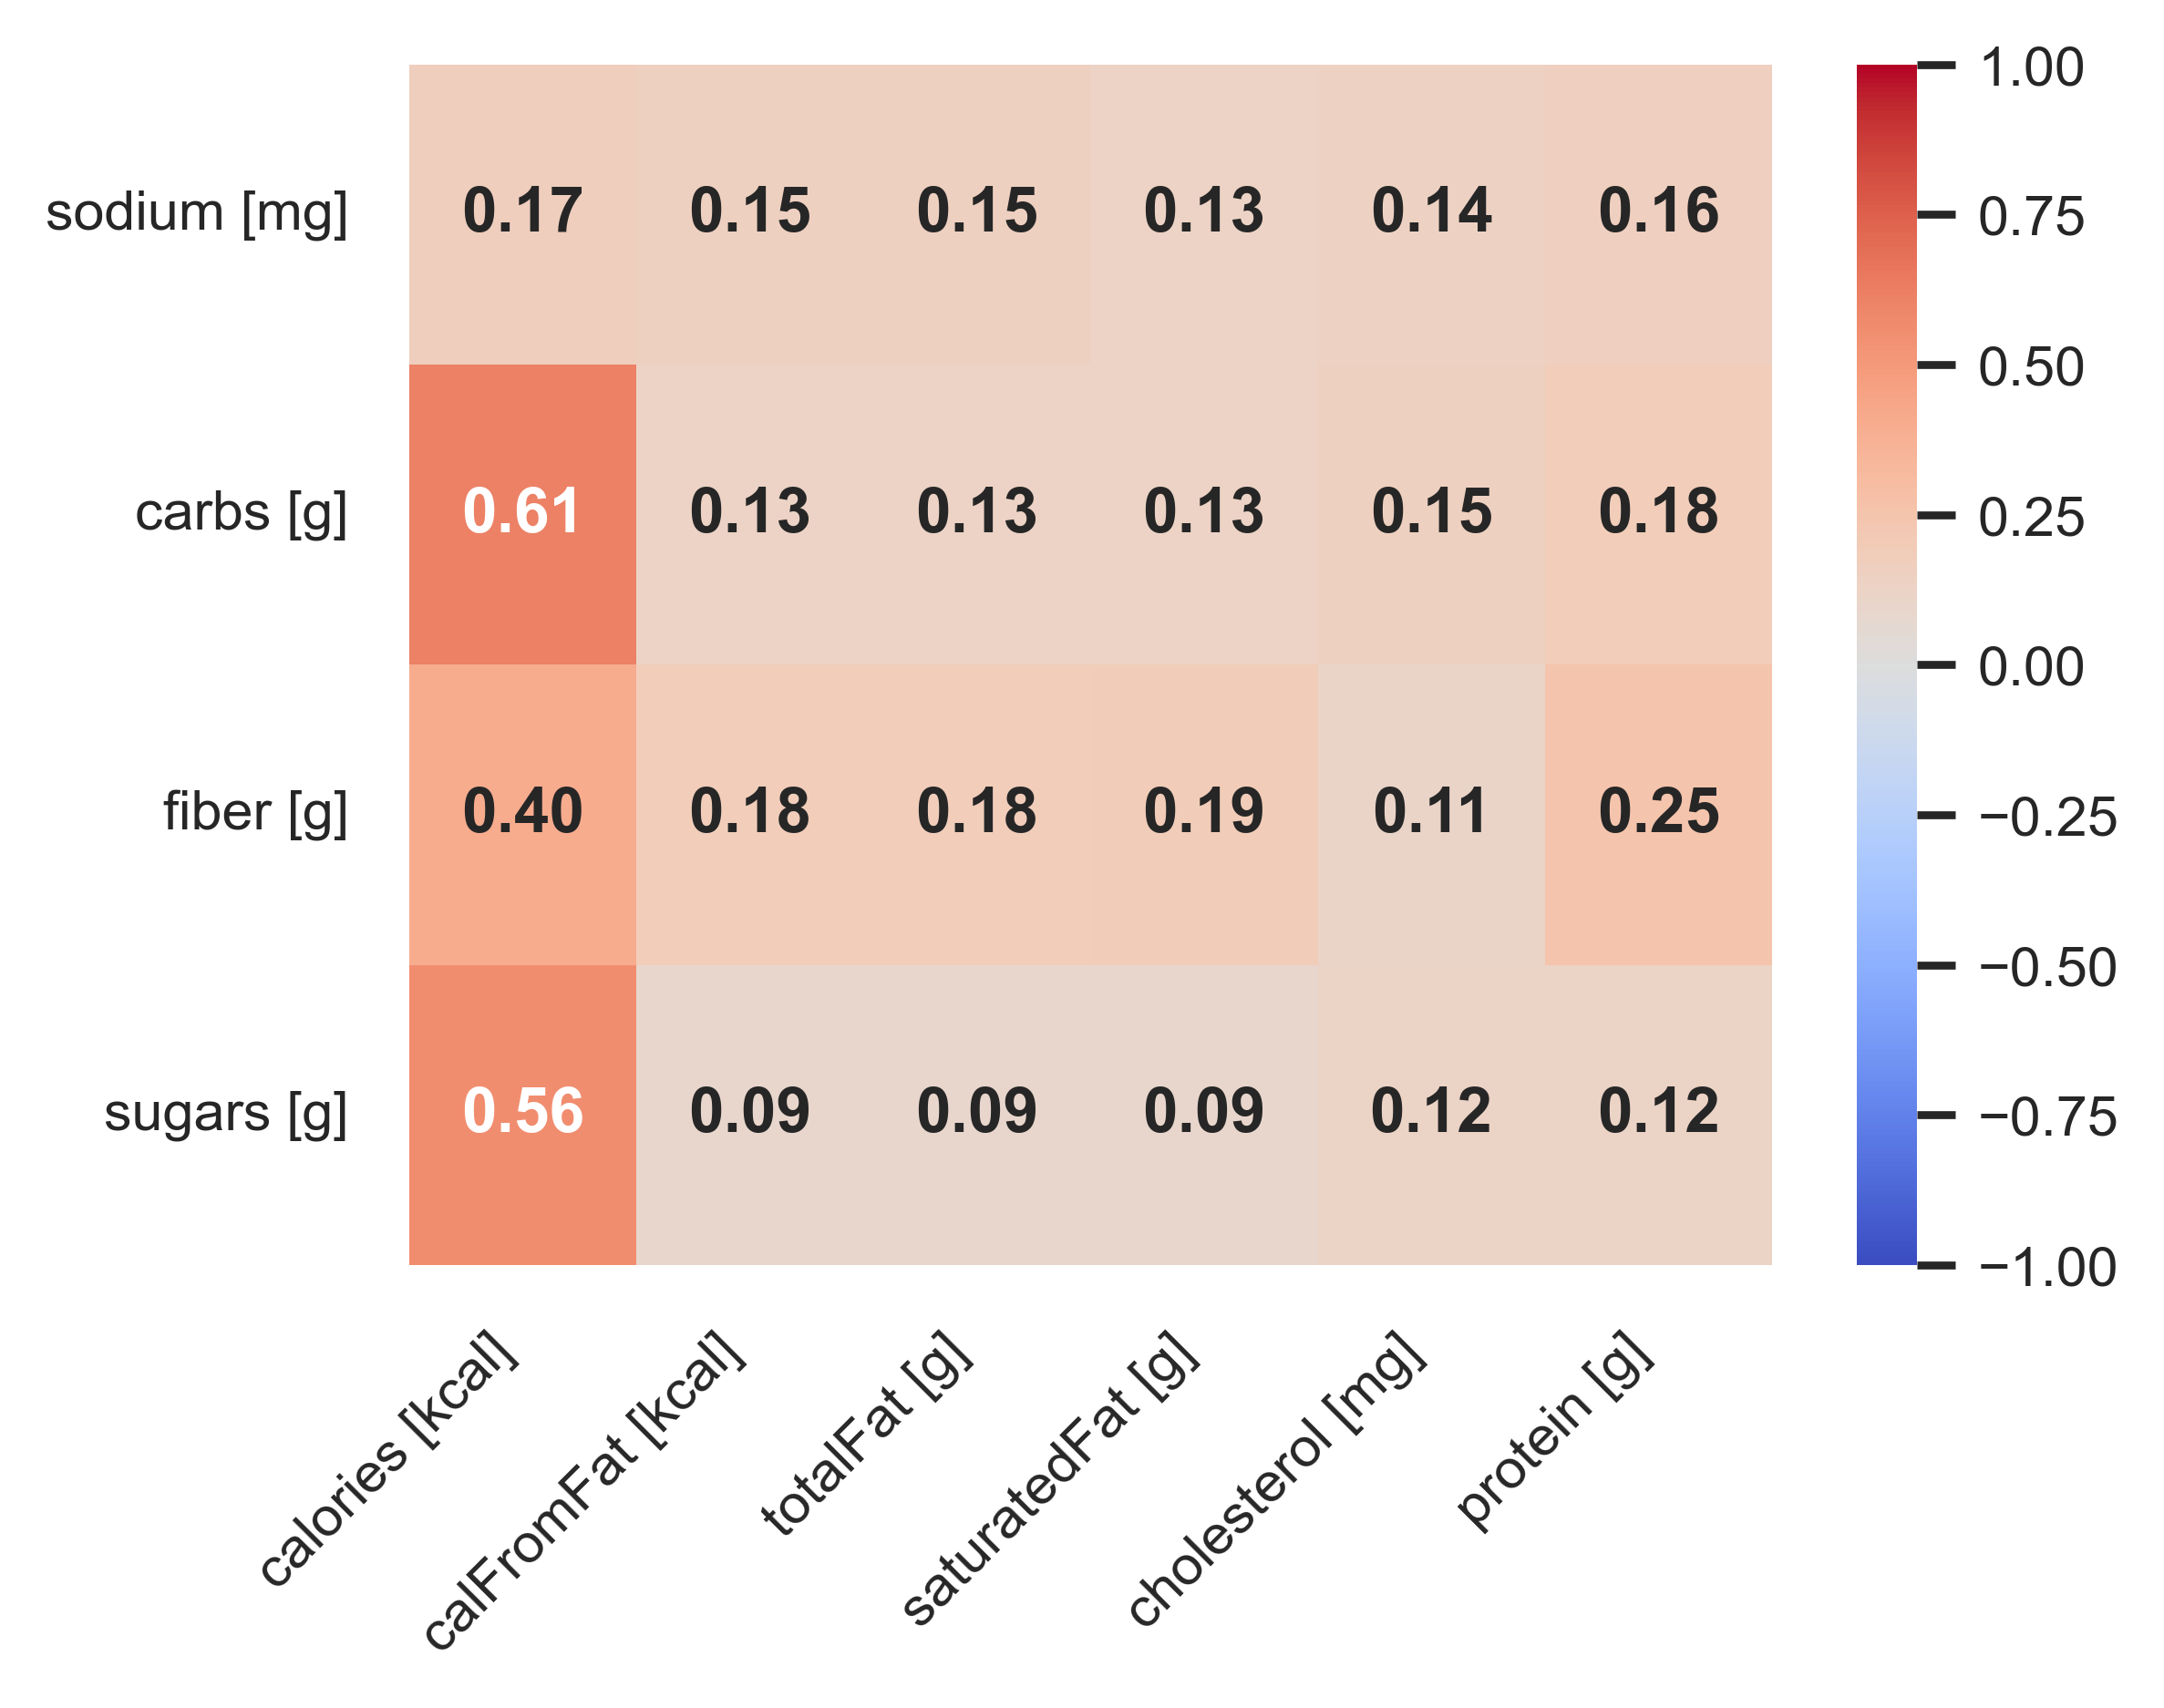

In [76]:
# hummus_heatmap_energy_other_nutrients.png
plt.rcParams.update({'font.size': 15})

plot_data = pd.DataFrame(recipes)
plot_data = plot_data.rename(
    columns={'direction_size': '#steps',
             'ingredients_sizes': '#ingred',
             'number_of_ratings': '#ratings',
             'average_rating': 'avgRating',
             'totalCarbohydrate [g]': 'carbs [g]',
             'caloriesFromFat [kcal]': 'calFromFat [kcal]',
             'dietaryFiber [g]': 'fiber [g]',
             }
)

# choose features
x_features = ['calories [kcal]', 'calFromFat [kcal]', 'totalFat [g]', 'saturatedFat [g]', 'cholesterol [mg]', 'protein [g]']
y_features = ['sodium [mg]', 'carbs [g]', 'fiber [g]', 'sugars [g]']

all_features = list(dict.fromkeys(y_features + x_features))
corr = plot_data[all_features].corr()
corr = corr.loc[y_features, x_features]

plt.figure(figsize=(5, 4), dpi=500)

sns.heatmap(
    corr.round(2),
    annot=True,
    fmt=".2f",
    annot_kws={"weight": "bold", "size": 10},
    cmap="coolwarm",
    vmin=-1,          # fixed minimum
    vmax=1,           # fixed maximum
    center=0,         # white at zero
    cbar=True
)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

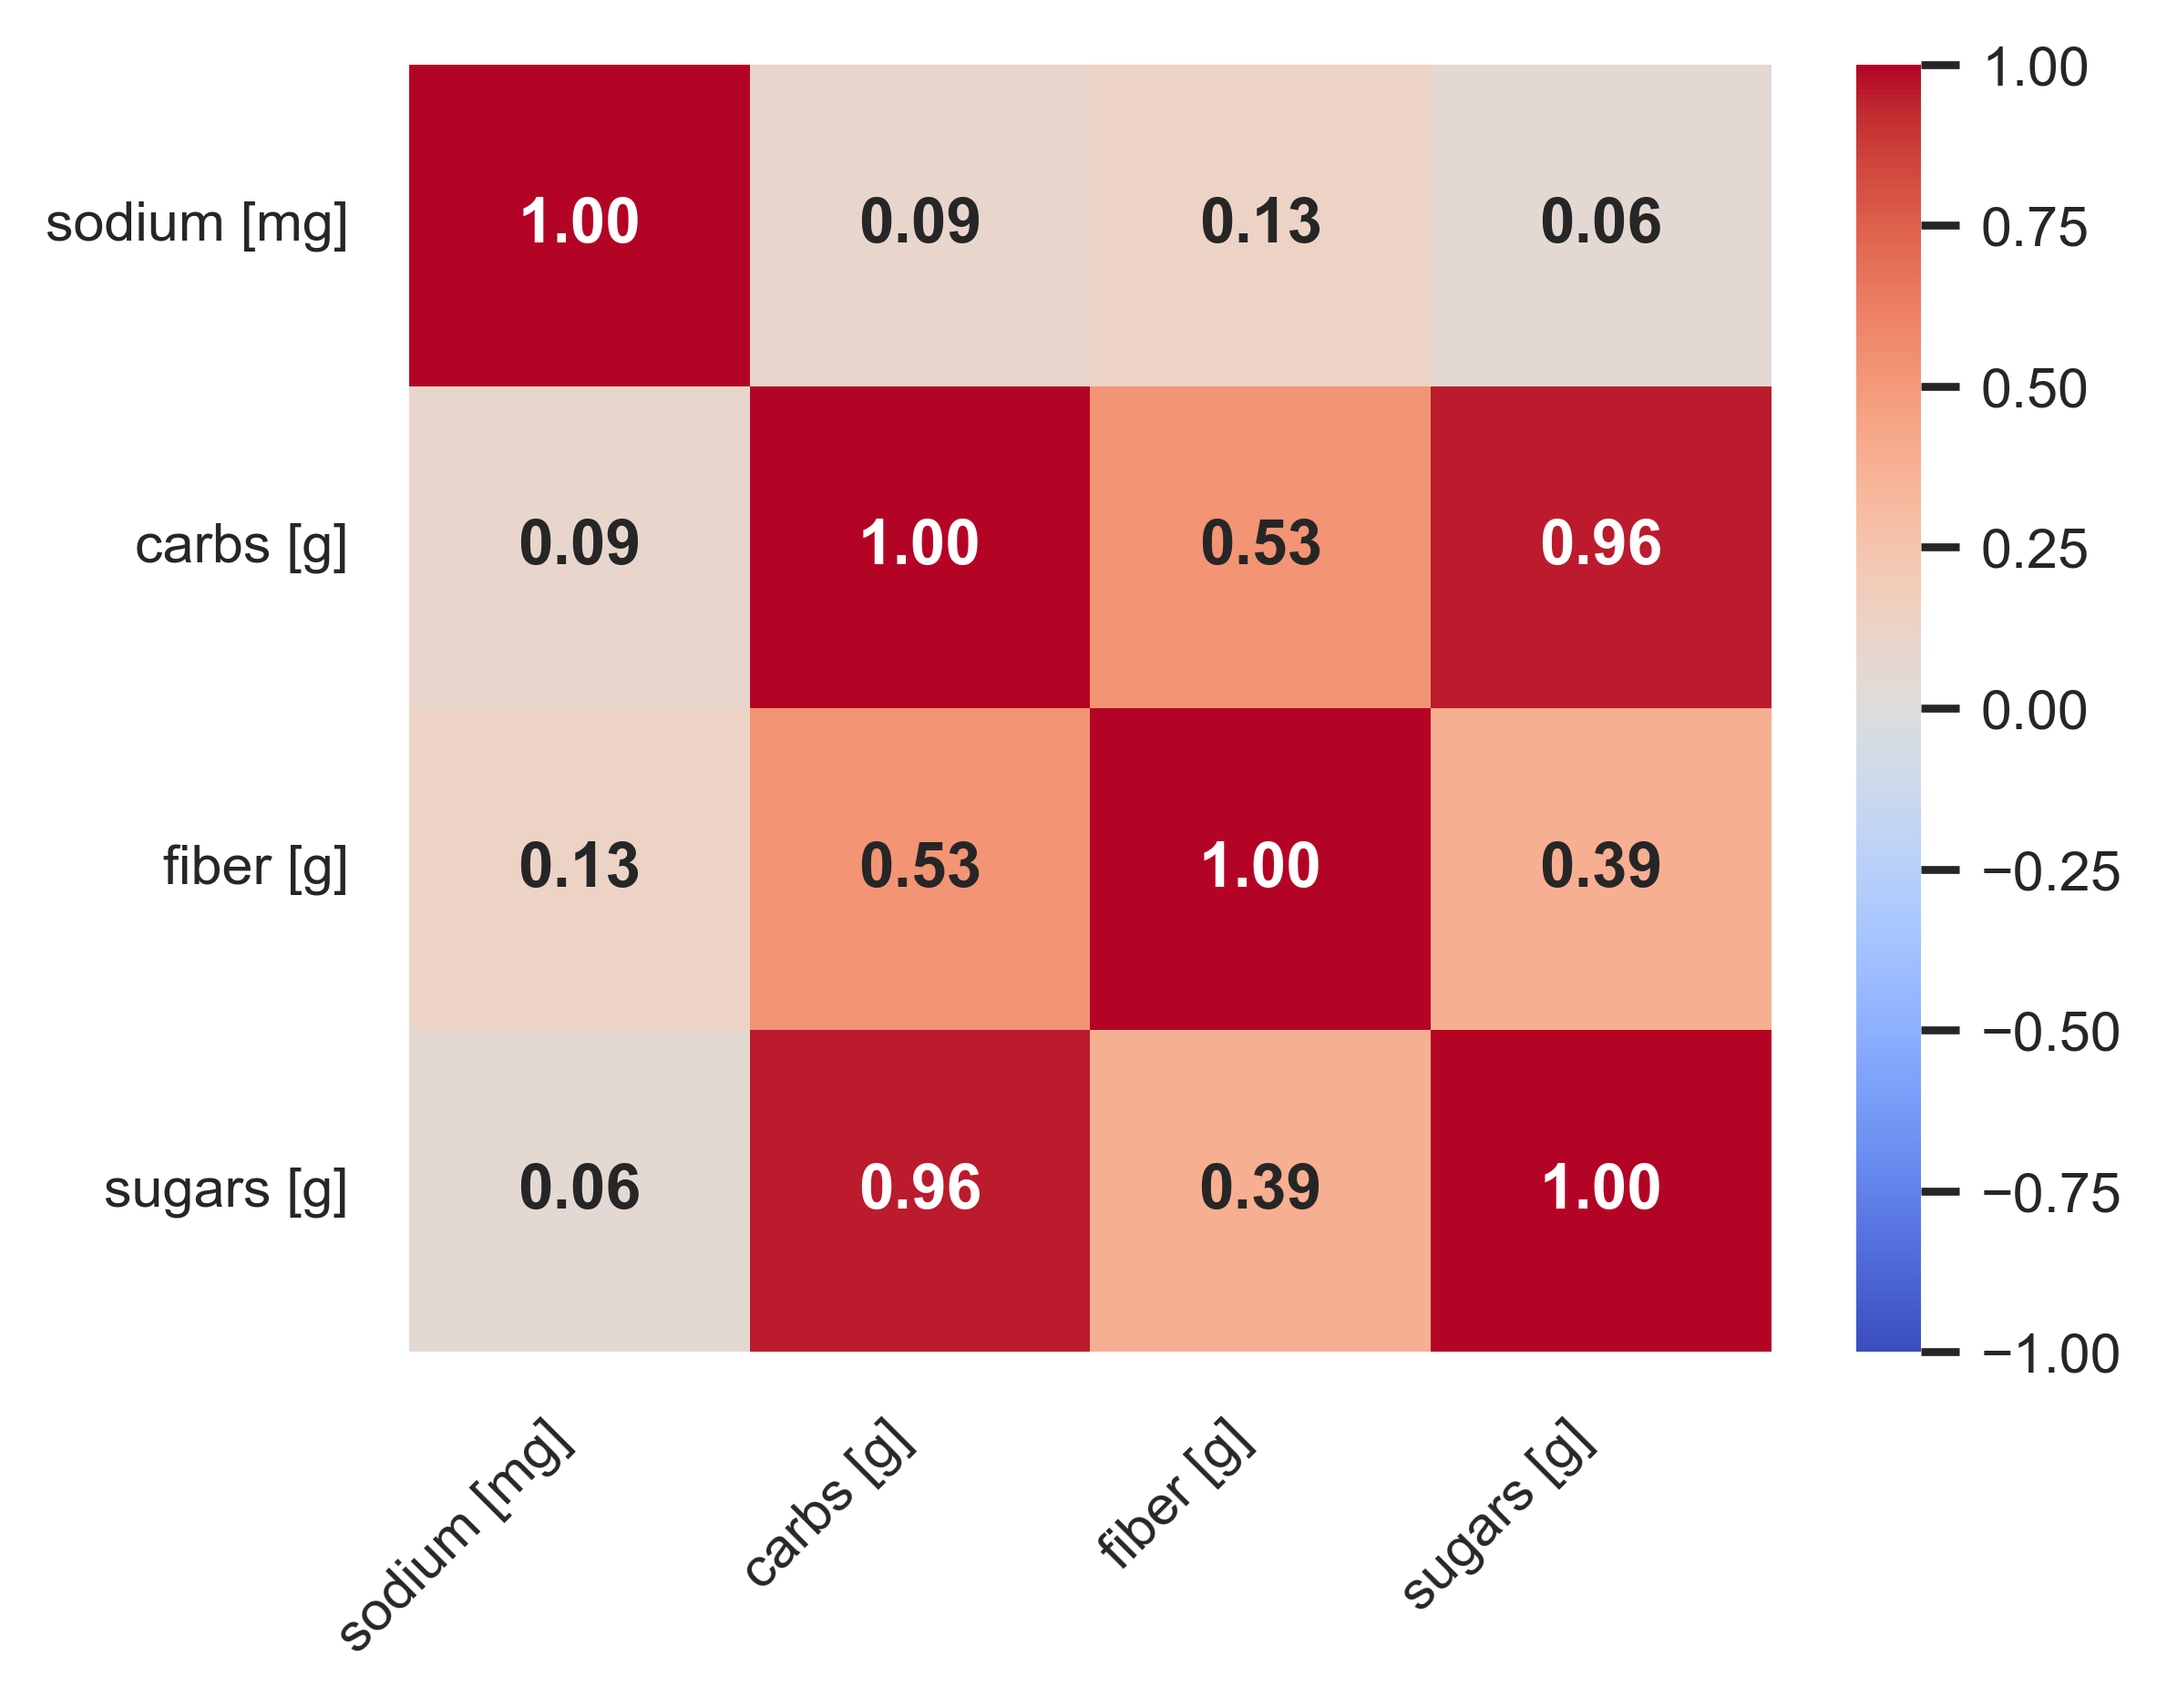

In [77]:
#hummus_heatmap_other_nutrients.png
plt.rcParams.update({'font.size': 15})

plot_data = pd.DataFrame(recipes)
plot_data = plot_data.rename(
    columns={'direction_size': '#steps',
             'ingredients_sizes': '#ingred',
             'number_of_ratings': '#ratings',
             'average_rating': 'avgRating',
             'totalCarbohydrate [g]': 'carbs [g]',
             'caloriesFromFat [kcal]': 'calFromFat [kcal]',
             'dietaryFiber [g]': 'fiber [g]',
             }
)

# choose features
x_features = ['sodium [mg]', 'carbs [g]', 'fiber [g]', 'sugars [g]']
y_features = ['sodium [mg]', 'carbs [g]', 'fiber [g]', 'sugars [g]']

all_features = list(dict.fromkeys(y_features + x_features))
corr = plot_data[all_features].corr()
corr = corr.loc[y_features, x_features]

plt.figure(figsize=(5, 4), dpi=500)

sns.heatmap(
    corr.round(2),
    annot=True,
    fmt=".2f",
    annot_kws={"weight": "bold", "size": 10},
    cmap="coolwarm",
    vmin=-1,          # fixed minimum
    vmax=1,           # fixed maximum
    center=0,         # white at zero
    cbar=True
)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

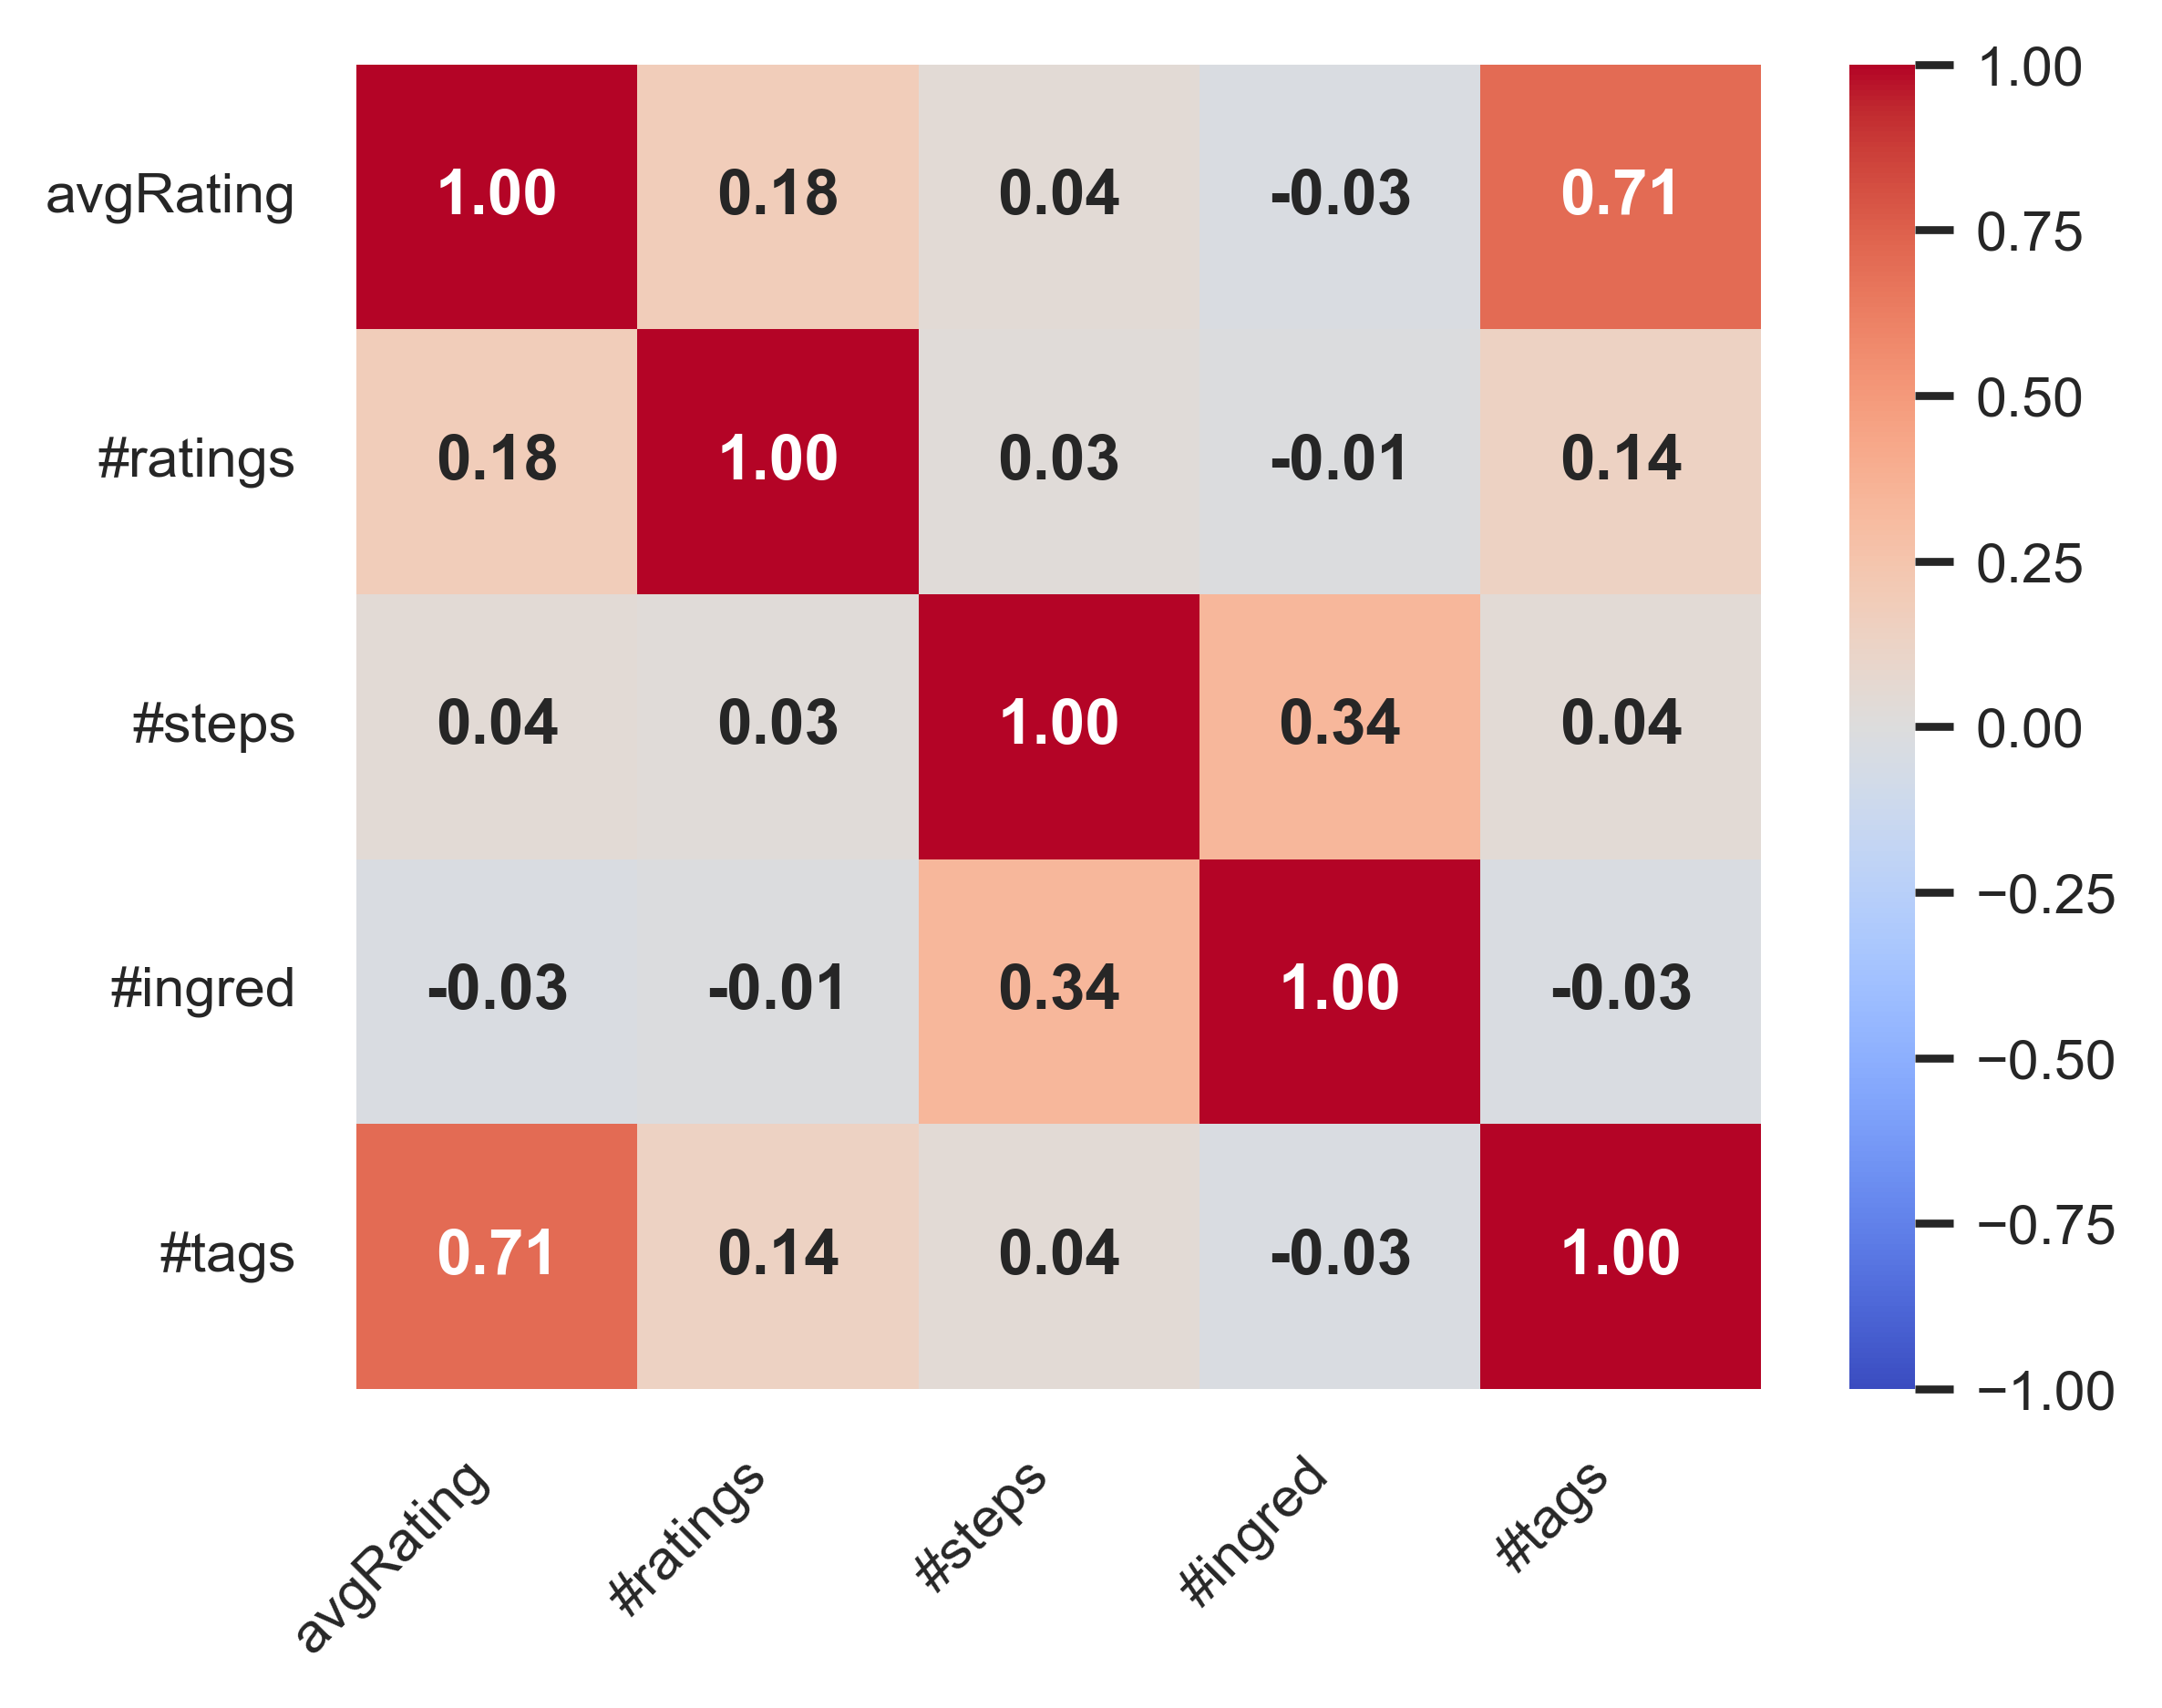

In [78]:
#hummus_heatmap_other_features.png
plt.rcParams.update({'font.size': 15})

plot_data = pd.DataFrame(recipes)
plot_data = plot_data.rename(
    columns={'direction_size': '#steps',
             'ingredients_sizes': '#ingred',
             'number_of_ratings': '#ratings',
             'average_rating': 'avgRating',
             'totalCarbohydrate [g]': 'carbs [g]',
             'caloriesFromFat [kcal]': 'calFromFat [kcal]',
             'dietaryFiber [g]': 'fiber [g]',
             }
)

# choose features
x_features = ['avgRating', '#ratings', '#steps', '#ingred', '#tags']
y_features = ['avgRating', '#ratings', '#steps', '#ingred', '#tags']

all_features = list(dict.fromkeys(y_features + x_features))
corr = plot_data[all_features].corr()
corr = corr.loc[y_features, x_features]

plt.figure(figsize=(5, 4), dpi=500)

sns.heatmap(
    corr.round(2),
    annot=True,
    fmt=".2f",
    annot_kws={"weight": "bold", "size": 10},
    cmap="coolwarm",
    vmin=-1,          # fixed minimum
    vmax=1,           # fixed maximum
    center=0,         # white at zero
    cbar=True
)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

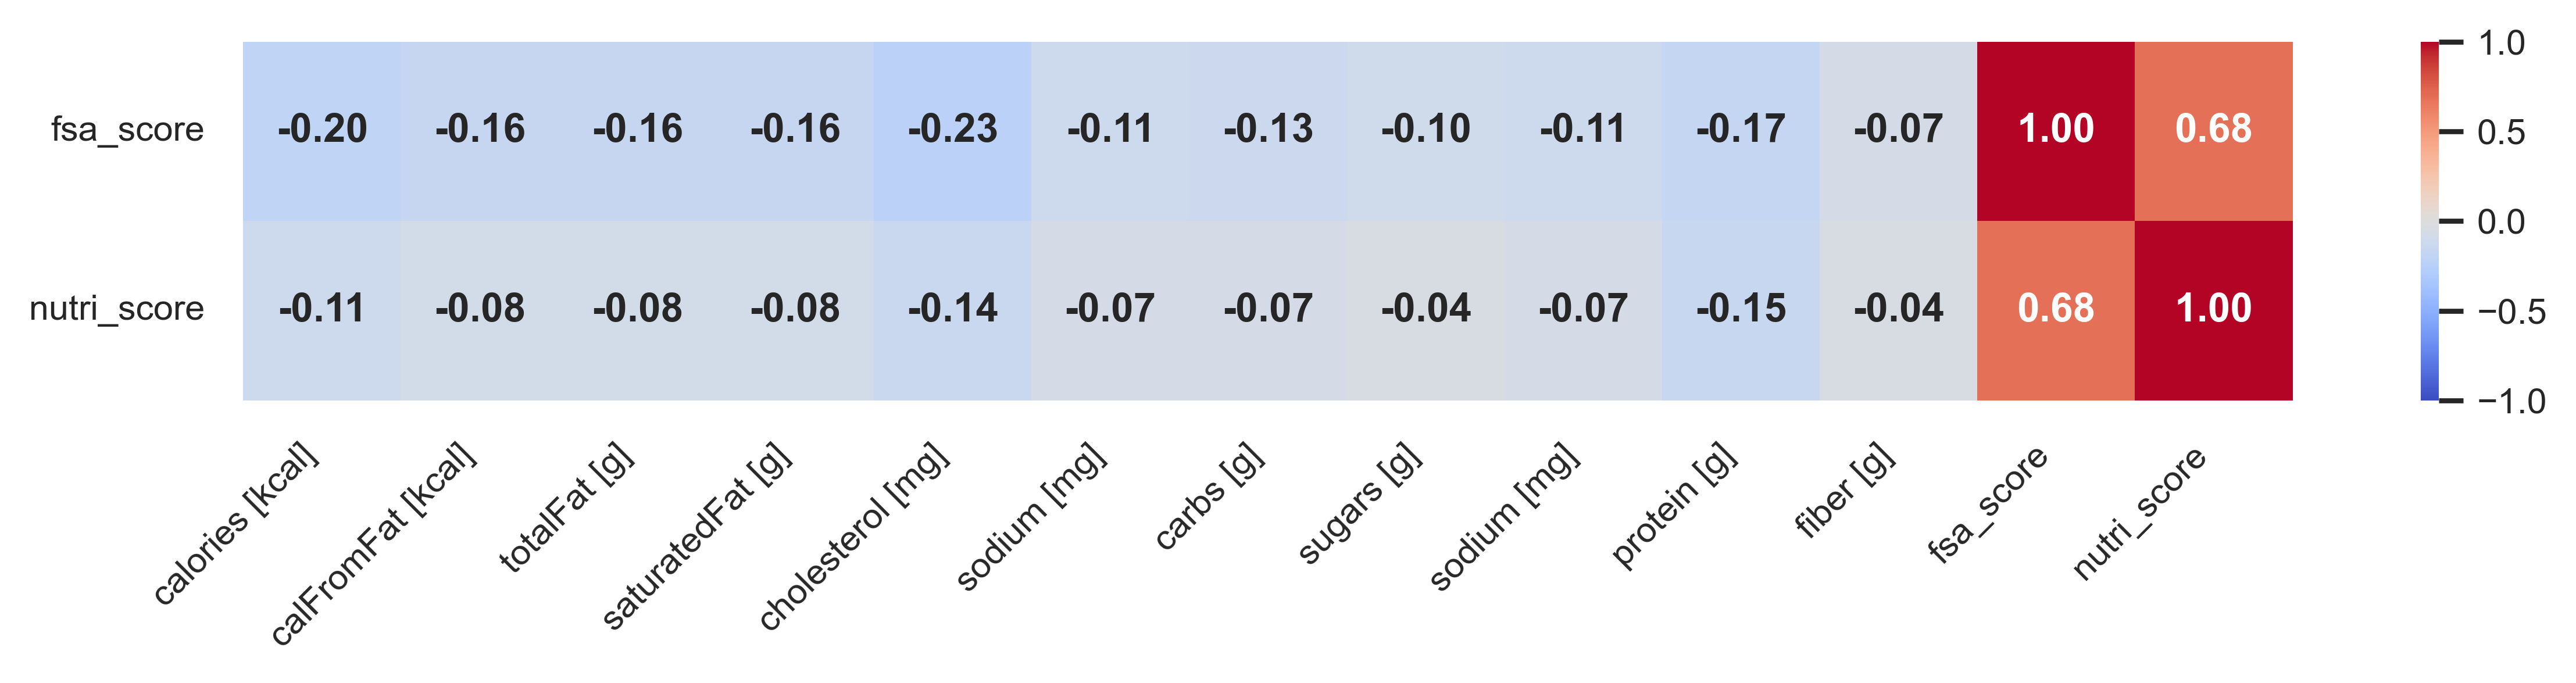

In [79]:
#hummus_heatmap_scores.png
plt.rcParams.update({'font.size': 15})

plot_data = pd.DataFrame(recipes)
plot_data = plot_data.rename(
    columns={'direction_size': '#steps',
             'ingredients_sizes': '#ingred',
             'number_of_ratings': '#ratings',
             'average_rating': 'avgRating',
             'totalCarbohydrate [g]': 'carbs [g]',
             'caloriesFromFat [kcal]': 'calFromFat [kcal]',
             'dietaryFiber [g]': 'fiber [g]',
             }
)

# choose features
x_features = ['calories [kcal]', 'calFromFat [kcal]', 'totalFat [g]', 'saturatedFat [g]', 'cholesterol [mg]', 'sodium [mg]', 'carbs [g]', 'sugars [g]', 'sodium [mg]', 'protein [g]', 'fiber [g]', 'fsa_score', 'nutri_score']
y_features = ['fsa_score', 'nutri_score']

all_features = list(dict.fromkeys(y_features + x_features))
corr = plot_data[all_features].corr()
corr = corr.loc[y_features, x_features]

plt.figure(figsize=(10, 2.6), dpi=500)

sns.heatmap(
    corr.round(2),
    annot=True,
    fmt=".2f",
    annot_kws={"weight": "bold", "size": 10},
    cmap="coolwarm",
    vmin=-1,          # fixed minimum
    vmax=1,           # fixed maximum
    center=0,         # white at zero
    cbar=True
)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()